# NITRC: классификация пациентских NIRS-сигналов


В этой части реализуется приближённая реконструкция online-классификатора из статьи для пациентского NIRS-датасета.

### Общий план классификации

Используются:

- **28 NIRS-каналов**;
- два типа гемодинамического сигнала:
  - `HbO` — oxyhemoglobin;
  - `HbR` — deoxyhemoglobin;
- итоговый вектор признаков на каждый временной отсчёт:

$$
x_t = [HbO_1,\ldots,HbO_{28}, HbR_1,\ldots,HbR_{28}],
$$

то есть всего **56 признаков** на отсчёт.

Классификация выполняется в два этапа:

1. **Stage 1: rest vs active**  
   Сначала классификатор отделяет состояние покоя от воображения движения.

2. **Stage 2: left vs right**  
   Если эпоха отнесена к active, второй классификатор определяет, какая рука воображалась: левая или правая.

Окна классификации:

- длина окна: **1 секунда**;
- шаг окна: **250 мс**;
- при частоте дискретизации `fs = 15.625 Hz` это примерно:
  - `16` отсчётов на окно;
  - `4` отсчёта на шаг.

Обучение идёт в online-like режиме:

- для текущего блока используются только данные, доступные до него:
  - предыдущие блоки текущей сессии;
  - предыдущие сессии этого пациента;
- первый блок пациента не оценивается, так как до него ещё нет обучающей истории.

In [1]:
from pathlib import Path
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from nirs_bci.nitrc import build_nitrc_file_table, evaluate_nitrc_all_subjects, summarize_online_like_blocks
from nirs_bci.evaluation import dissertation_score_fixed_labels
from nirs_bci.visualization import plot_author_boxplot_like_matlab

ROOT = Path.cwd().resolve()
ROOT = next(
    (folder for folder in (ROOT, *ROOT.parents)
     if (folder / "pyproject.toml").is_file() and (folder / "configs").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук внутри каталога проекта nirs-bci-classification.")
config = yaml.safe_load((ROOT / "configs/nitrc.yaml").read_text(encoding="utf-8"))
data_root = ROOT / config["paths"]["data_root"]
concentrations_dir = data_root / config["paths"]["concentrations_dir"]
classification_dir = data_root / config["paths"]["classification_dir"]
results_dir = ROOT / config["paths"]["output_root"]
results_dir.mkdir(parents=True, exist_ok=True)


## Сравнение с данными статьи

,Subject,Day,Session,RecallValue,CM11,CM12,CM13,CM21,CM22,CM23,CM31,CM32,CM33
0,1,1,1,0.564514,519,44,74,14,45,9,95,220,215
1,1,2,2,0.335304,432,170,197,89,1,16,295,241,192
2,1,3,3,0.561097,676,138,85,52,165,142,87,110,189
3,1,4,4,0.315610,377,232,227,176,91,73,282,94,115
4,1,5,5,0.451930,456,193,102,27,43,20,352,176,292


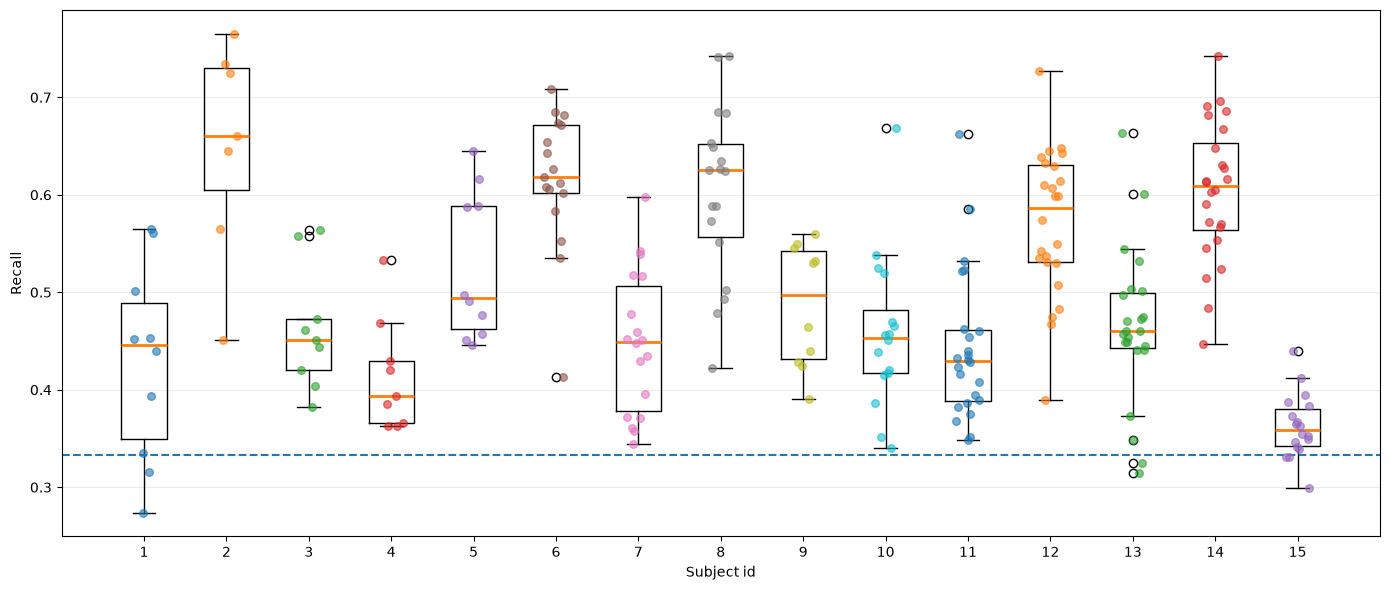

In [ ]:
summary_path = classification_dir / "classification_summary.csv"
author_df = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame()
if not author_df.empty:
    display(author_df.head())
else:
    print("Авторская сводка отсутствует:", summary_path)

if not author_df.empty:
    fig, ax = plot_author_boxplot_like_matlab(author_df)
    plt.show()


## Воспроизведение базового классификатора

### Загрузка данных

In [3]:
if not list(concentrations_dir.glob("*_concentrations.mat")):
    raise FileNotFoundError(f"Добавьте *_concentrations.mat в {concentrations_dir}")
file_table = build_nitrc_file_table(concentrations_dir)
display(file_table[["file", "subject", "day", "session"]].head())
print("n concentration files:", len(file_table))
print("subjects:", sorted(file_table["subject"].unique()))


,file,subject,day,session
0,Subject1_day1_session1_concentrations.mat,1,1,1
1,Subject1_day2_session2_concentrations.mat,1,2,2
2,Subject1_day3_session3_concentrations.mat,1,3,3
3,Subject1_day4_session4_concentrations.mat,1,4,4
4,Subject1_day5_session5_concentrations.mat,1,5,5


n concentration files: 237
subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


### Запуск классификации

In [4]:
all_epochs, all_blocks = [], []
for cfg in config["regularization"]:
    print(f"\n=== {cfg['name']} ===")
    epochs, blocks = evaluate_nitrc_all_subjects(
        file_table,
        training_modes=config["evaluation"]["training_modes"],
        filter_mode=config["evaluation"]["filter_mode"],
        epoch_sec=config["evaluation"]["epoch_sec"],
        step_sec=config["evaluation"]["step_sec"],
        label_rule=config["evaluation"]["label_rule"],
        covariance_reg=config["evaluation"]["covariance_reg"],
        covariance_shrinkage=cfg["covariance_shrinkage"],
        shrinkage_alpha=cfg["shrinkage_alpha"],
        verbose=config["evaluation"]["verbose"],
    )
    epochs["config"] = cfg["name"]
    blocks["config"] = cfg["name"]
    all_epochs.append(epochs)
    all_blocks.append(blocks)
epoch_results_all = pd.concat(all_epochs, ignore_index=True)
block_results_all = pd.concat(all_blocks, ignore_index=True)
display(summarize_online_like_blocks(block_results_all))
epoch_results_all.to_csv(results_dir / "epoch_results.csv", index=False)
block_results_all.to_csv(results_dir / "block_results.csv", index=False)



=== none ===

=== diagonal_0.010 ===


,training_mode,filter_mode,label_rule,covariance_reg,covariance_shrinkage,shrinkage_alpha,n_blocks,median,q25,q75,recall_str
0,previous_blocks_and_sessions,causal,strict,0.0,diagonal,0.01,1309,0.530082,0.392424,0.660592,0.5301 [0.3924; 0.6606]
1,previous_blocks_and_sessions,causal,strict,0.0,none,0.00,1309,0.521188,0.385029,0.675569,0.5212 [0.3850; 0.6756]


### Расчёт recall по сессиям

In [5]:
group_cols = [
    "config", "subject", "day", "session", "file", "training_mode",
    "filter_mode", "label_rule", "covariance_reg",
    "covariance_shrinkage", "shrinkage_alpha",
]
group_cols = [col for col in group_cols if col in epoch_results_all.columns]
rows = []
for keys, group in epoch_results_all.groupby(group_cols, dropna=False):
    keys = keys if isinstance(keys, tuple) else (keys,)
    recall, cm, _ = dissertation_score_fixed_labels(
        group["y_true"].astype(int).to_numpy(),
        group["y_pred"].astype(int).to_numpy(),
        labels=[1, 2, 3],
    )
    # Для сохранения исходного соглашения таблицы: строки = true, столбцы = predicted.
    rows.append({
        **dict(zip(group_cols, keys)),
        "RecallValue": recall,
        "n_epochs": len(group),
        "confusion_matrix": cm.T,
    })
session_results_all = pd.DataFrame(rows)
display(session_results_all.head())


,config,subject,day,session,file,training_mode,filter_mode,label_rule,covariance_reg,covariance_shrinkage,shrinkage_alpha,RecallValue,n_epochs,confusion_matrix
0,diagonal_0.010,1,1,1,Subject1_day1_session1_concentrations.mat,previous_blocks_and_sessions,causal,strict,0.0,diagonal,0.01,0.642816,1316,"[[564, 17, 77], [43, 101, 186], [74, 3, 251]]"
1,diagonal_0.010,1,2,2,Subject1_day2_session2_concentrations.mat,previous_blocks_and_sessions,causal,strict,0.0,diagonal,0.01,0.381713,1759,"[[582, 124, 173], [229, 3, 207], [99, 132, 210]]"
2,diagonal_0.010,1,3,3,Subject1_day3_session3_concentrations.mat,previous_blocks_and_sessions,causal,strict,0.0,diagonal,0.01,0.600231,1757,"[[704, 98, 78], [77, 133, 228], [83, 50, 306]]"
3,diagonal_0.010,1,4,4,Subject1_day4_session4_concentrations.mat,previous_blocks_and_sessions,causal,strict,0.0,diagonal,0.01,0.251684,1752,"[[423, 180, 273], [292, 13, 134], [201, 130, 1..."
4,diagonal_0.010,1,5,5,Subject1_day5_session5_concentrations.mat,previous_blocks_and_sessions,causal,strict,0.0,diagonal,0.01,0.384305,1757,"[[475, 100, 303], [171, 106, 162], [242, 35, 1..."


### Результаты по сессиям

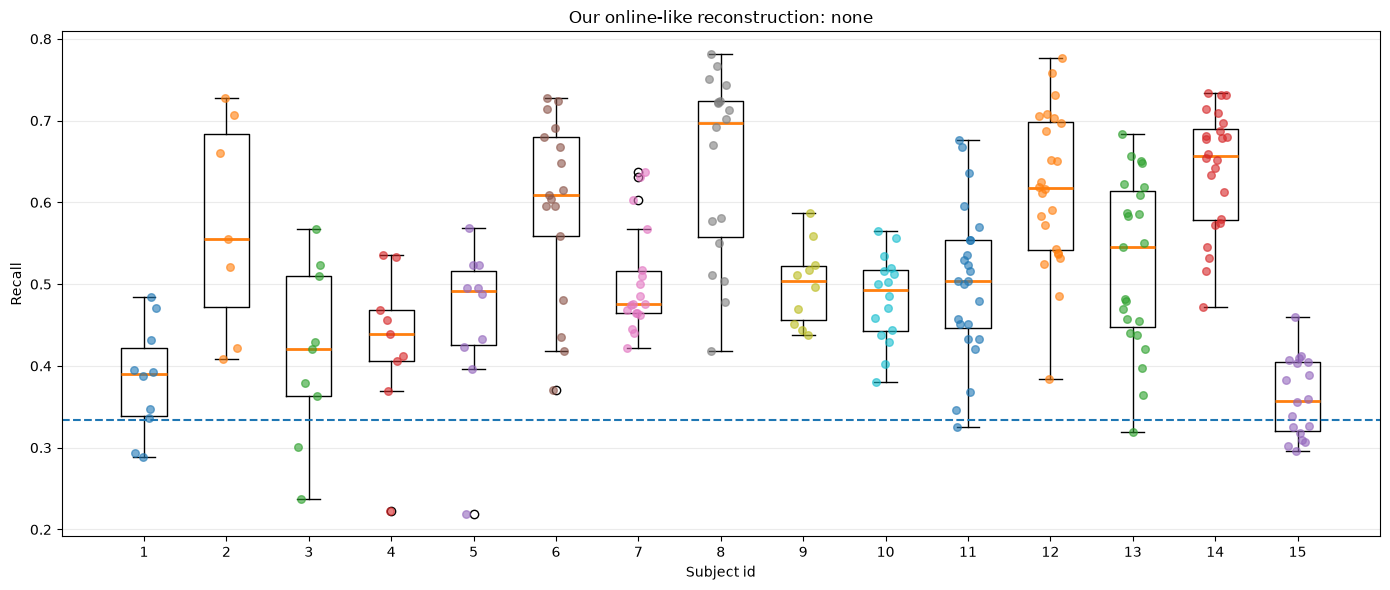

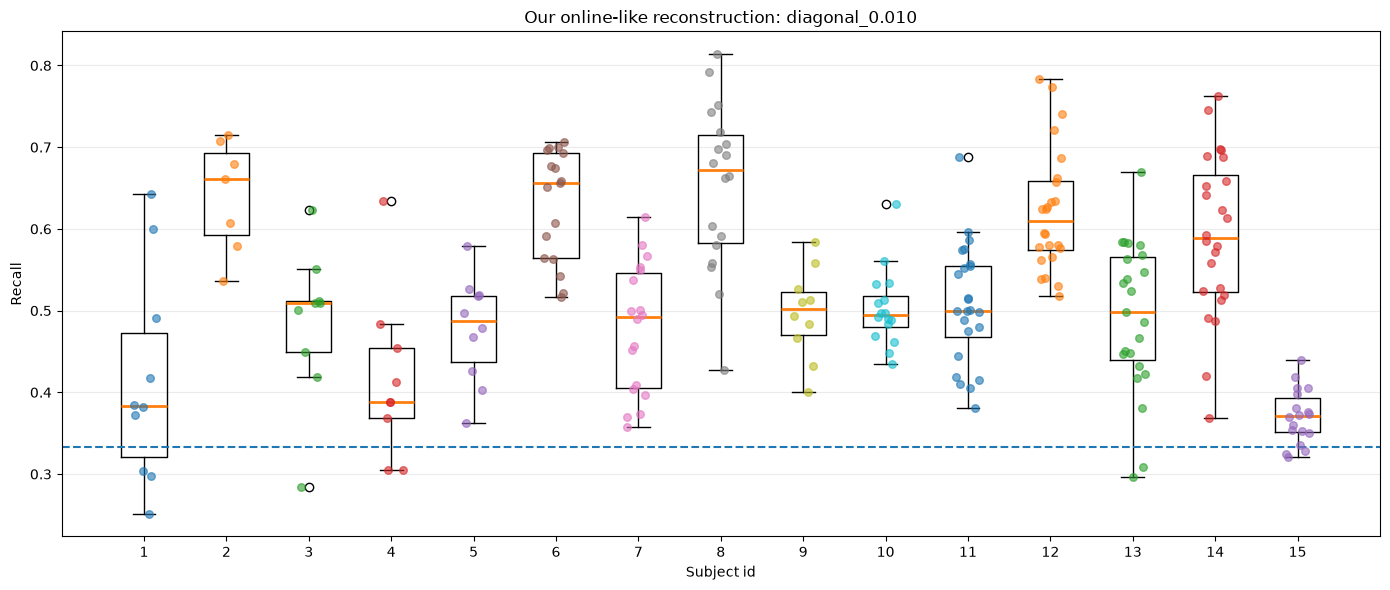

In [6]:
for cfg_name in config["plot_configs"]:
    plot_df = session_results_all.loc[session_results_all["config"] == cfg_name]
    fig, ax = plot_author_boxplot_like_matlab(
        plot_df, subject_col="subject", recall_col="RecallValue",
        title=f"Our online-like reconstruction: {cfg_name}",
    )
    plt.show()
    fig.savefig(results_dir / f"recall_{cfg_name}.png", dpi=300, bbox_inches="tight")


### Агрегация по пациентам и сравнение регуляризации

In [7]:
our_subject_summary = (
    session_results_all
    .groupby(["config", "subject"], as_index=False)
    .agg(
        n_sessions=("RecallValue", "count"),
        median_recall=("RecallValue", "median"),
        min_recall=("RecallValue", "min"),
        max_recall=("RecallValue", "max"),
    )
)

our_subject_summary["within_subject_range"] = (
    our_subject_summary["max_recall"] - our_subject_summary["min_recall"]
)

our_summary = (
    our_subject_summary
    .groupby("config", as_index=False)
    .agg(
        n_subjects=("subject", "count"),

        grand_median=("median_recall", "median"),
        grand_q25=("median_recall", lambda x: x.quantile(0.25)),
        grand_q75=("median_recall", lambda x: x.quantile(0.75)),

        within_median=("within_subject_range", "median"),
        within_q25=("within_subject_range", lambda x: x.quantile(0.25)),
        within_q75=("within_subject_range", lambda x: x.quantile(0.75)),
    )
)

our_summary["grand_median_recall"] = our_summary.apply(
    lambda r: f"{100*r['grand_median']:.1f}% "
              f"[{100*r['grand_q25']:.1f}; {100*r['grand_q75']:.1f}]%",
    axis=1,
)

our_summary["within_subject_range"] = our_summary.apply(
    lambda r: f"{100*r['within_median']:.1f}% "
              f"[{100*r['within_q25']:.1f}; {100*r['within_q75']:.1f}]%",
    axis=1,
)

display(
    our_summary[
        [
            "config",
            "n_subjects",
            "grand_median_recall",
            "within_subject_range",
        ]
    ]
)
session_results_all.to_csv(results_dir / "session_results.csv", index=False)
our_subject_summary.to_csv(results_dir / "subject_summary.csv", index=False)
our_summary.to_csv(results_dir / "summary.csv", index=False)

for _, r in our_summary.iterrows():
    print(f"{r['config']}")
    print(f"  grand median recall: {r['grand_median_recall']}")
    print(f"  within-subject range: {r['within_subject_range']}")


,config,n_subjects,grand_median_recall,within_subject_range
0,diagonal_0.010,15,50.0% [49.0; 59.9]%,26.5% [19.2; 35.6]%
1,none,15,50.4% [45.7; 58.3]%,31.9% [20.6; 35.4]%


diagonal_0.010
  grand median recall: 50.0% [49.0; 59.9]%
  within-subject range: 26.5% [19.2; 35.6]%
none
  grand median recall: 50.4% [45.7; 58.3]%
  within-subject range: 31.9% [20.6; 35.4]%


**Авторский результат онлайн-классификации**

В статье в качестве метрики качества online-классификации использовался средний recall по трём классам:

$$
P = \frac{1}{3}\sum_{i=1}^{3}
\frac{c_{ii}}{\sum_{j=1}^{3} c_{ji}},
$$

где \(c_{ij}\) — элементы матрицы ошибок. В соглашении авторов строки матрицы соответствуют ответам классификатора, а столбцы — предъявленным инструкциям. Поэтому знаменатель \(\sum_j c_{ji}\) задаёт число объектов истинного класса \(i\).

Для всех пациентов авторы получили:

$$
P_{\mathrm{grand\ median}} = 46.0\% \; [44.7\%; 60.3\%].
$$

Все пациенты превысили случайный уровень классификации \(1/3\). При этом качество классификации заметно варьировало как между пациентами, так и между сессиями внутри большинства пациентов. Медианный внутрипациентский размах session recall составил:

$$
29.5\% \; [18.6\%; 31.8\%].
$$